In [ ]:
import os
import urllib.request
import zipfile
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.layers import Conv1D, Dense, Dropout, Input, LSTM, MaxPooling1D
from tensorflow.keras.models import Sequential

# 1. UNDUH & EKSTRAK DATASET RESMI UCI ID 240 OTOMATIS
url = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
if not os.path.exists("har.zip"):
  print("Mengunduh dataset UCI HAR...")
  urllib.request.urlretrieve(url, "har.zip")

with zipfile.ZipFile("har.zip", "r") as z:
  z.extractall("har_raw")

if os.path.exists("har_raw/UCI HAR Dataset.zip"):
  with zipfile.ZipFile("har_raw/UCI HAR Dataset.zip", "r") as z2:
    z2.extractall("har_data")
  base_dir = "har_data/UCI HAR Dataset"
else:
  base_dir = "har_raw/UCI HAR Dataset"

# 2. BACA DATA TRAIN, TEST, & LABEL AKTIVITAS
X_train_full = pd.read_csv(
    f"{base_dir}/train/X_train.txt", sep=r"\s+", header=None
).values
y_train_full = (
    pd.read_csv(f"{base_dir}/train/y_train.txt", header=None).values.ravel() - 1
)

X_test = pd.read_csv(
    f"{base_dir}/test/X_test.txt", sep=r"\s+", header=None
).values
y_test = (
    pd.read_csv(f"{base_dir}/test/y_test.txt", header=None).values.ravel() - 1
)

activity_names = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING",
]

# 3. SPLIT VALIDATION & NORMALISASI (MENCEGAH DATA LEAKAGE)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full,
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)  # Fit hanya di data train
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# Ubah bentuk data menjadi 3D (jumlah_data, 561_fitur, 1_channel) agar bisa dibaca Conv1D
X_train_3d = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_val_3d = X_val.reshape((X_val.shape[0], X_val.shape[1], 1))
X_test_3d = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

print(
    f"Bentuk data siap latih -> Train: {X_train_3d.shape}, Val:"
    f" {X_val_3d.shape}, Test: {X_test_3d.shape}"
)

# 4. BANGUN ARSITEKTUR BASELINE CNN-LSTM
model = Sequential([
    Input(shape=(561, 1)),
    Conv1D(filters=32, kernel_size=3, activation="relu"),
    MaxPooling1D(pool_size=2),
    LSTM(64),
    Dropout(0.3),
    Dense(6, activation="softmax"),
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

# 5. LATIH MODEL (TRAINING)
history = model.fit(
    X_train_3d,
    y_train,
    validation_data=(X_val_3d, y_val),
    epochs=10,
    batch_size=64,
    verbose=1,
)

# 6. EVALUASI PADA DATA TEST
y_pred_prob = model.predict(X_test_3d)
y_pred = np.argmax(y_pred_prob, axis=1)

print("\n=== HASIL BASELINE CNN-LSTM ===")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred, target_names=activity_names))

# Contoh output 1 sampel (ini yang nantinya masuk ke Fuzzy Logic)
sample_idx = 0
print(
    f"Contoh Prediksi Sampel #0 -> Asli: {activity_names[y_test[sample_idx]]} |"
    f" Tebakan AI: {activity_names[y_pred[sample_idx]]}"
)
print(
    "Probabilitas tiap kelas:"
    f" {np.round(y_pred_prob[sample_idx], 3)} (Keyakinan tertinggi:"
    f" {np.max(y_pred_prob[sample_idx]):.3f})"
)

Mengunduh dataset UCI HAR...
Bentuk data siap latih -> Train: (5881, 561, 1), Val: (1471, 561, 1), Test: (2947, 561, 1)
Epoch 1/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 22s 217ms/step - accuracy: 0.4263 - loss: 1.2482 - val_accuracy: 0.5751 - val_loss: 0.9703
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 20s 217ms/step - accuracy: 0.5776 - loss: 0.8899 - val_accuracy: 0.6594 - val_loss: 0.7446
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 19s 204ms/step - accuracy: 0.6519 - loss: 0.7373 - val_accuracy: 0.7498 - val_loss: 0.6271
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 18s 201ms/step - accuracy: 0.7298 - loss: 0.6178 - val_accuracy: 0.7852 - val_loss: 0.5369
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 20s 197ms/step - accuracy: 0.7781 - loss: 0.5500 - val_accuracy: 0.8192 - val_loss: 0.5008
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 18s 197ms/step - accuracy: 0.8055 - loss: 0.5063 - val_accuracy: 0.8532 - val_loss: 0.4139
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 20s 215ms/step - accuracy: 0.8332 - loss: 0.4382 - val_accuracy: 0.8

# ==============================================================================
# RINGKASAN ALUR SEL 1 (BASELINE CNN-LSTM - KELOMPOK A6)
# 1. Download & Ekstrak : Mengunduh otomatis dataset UCI HAR (ID 240) lalu mengekstrak file ZIP-nya.
# 2. Load Data          : Membaca fitur input (561 sensor) dan label target (6 aktivitas) untuk Train & Test.
# 3. Split & Scaling    :
#    - Membagi data latih menjadi 80% Train & 20% Validation (stratified agar proporsi kelas tetap imbang).
#    - Menormalisasi skala angka memakai StandardScaler (fit hanya di Train agar tidak terjadi data leakage).
#    - Mengubah bentuk data (reshape) dari 2D ke 3D (sampel, 561, 1) supaya bisa dibaca layer Conv1D.
# 4. Arsitektur Model   : Menyusun lapisan Input -> Conv1D -> MaxPooling1D -> LSTM -> Dropout -> Dense (6 kelas).
# 5. Training           : Melatih model selama 10 epoch (batch_size=64) sambil memantau akurasi Validation.
# 6. Evaluasi           : Menguji akurasi akhir pada data Test dan mencetak probabilitas prediksi untuk Fuzzy Logic.
==============================================================================

=== RINGKASAN KUALITAS DATASET (EDA) ===
Total Sampel Data  : 10299 baris (Train: 7352, Test: 2947)
Jumlah Fitur Sensor: 561 fitur
Missing Values     : Train = 0 | Test = 0
Rentang Nilai Mentah (sebelum scaling): Min = -1.00, Max = 1.00, Mean = -0.51, Std = 0.53

=== DISTRIBUSI SAMPEL PER KELAS AKTIVITAS ===
         Aktivitas  Train  Test  Total  Persentase (%)
           WALKING   1226   496   1722           16.72
  WALKING_UPSTAIRS   1073   471   1544           14.99
WALKING_DOWNSTAIRS    986   420   1406           13.65
           SITTING   1286   491   1777           17.25
          STANDING   1374   532   1906           18.51
            LAYING   1407   537   1944           18.88


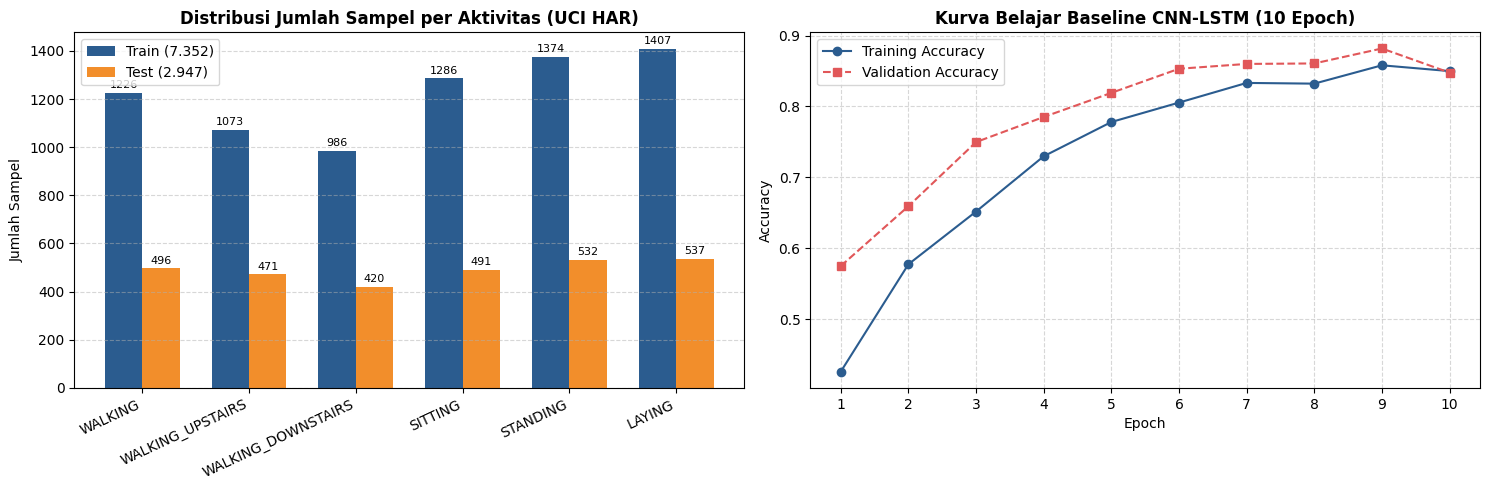

In [2]:
# Sel 2: Mengecek kualitas data (missing values), menghitung distribusi jumlah sampel per aktivitas, serta menampilkan grafik EDA dan kurva belajar Baseline CNN-LSTM untuk laporan Minggu 12.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. CEK KUALITAS DATA, MISSING VALUES, & STATISTIK FITUR
nan_train = np.isnan(X_train_full).sum()
nan_test = np.isnan(X_test).sum()

print("=== RINGKASAN KUALITAS DATASET (EDA) ===")
print(f"Total Sampel Data  : {len(X_train_full) + len(X_test)} baris (Train: {len(X_train_full)}, Test: {len(X_test)})")
print(f"Jumlah Fitur Sensor: {X_train_full.shape[1]} fitur")
print(f"Missing Values     : Train = {nan_train} | Test = {nan_test}")
print(f"Rentang Nilai Mentah (sebelum scaling): Min = {X_train_full.min():.2f}, Max = {X_train_full.max():.2f}, Mean = {X_train_full.mean():.2f}, Std = {X_train_full.std():.2f}\n")

# 2. CEK KESEIMBANGAN KELAS (CLASS IMBALANCE)
train_counts = pd.Series(y_train_full).value_counts().sort_index()
test_counts = pd.Series(y_test).value_counts().sort_index()

eda_df = pd.DataFrame({
    "Aktivitas": activity_names,
    "Train": train_counts.values,
    "Test": test_counts.values,
    "Total": train_counts.values + test_counts.values,
})
eda_df["Persentase (%)"] = (eda_df["Total"] / eda_df["Total"].sum() * 100).round(2)

print("=== DISTRIBUSI SAMPEL PER KELAS AKTIVITAS ===")
print(eda_df.to_string(index=False))

# 3. VISUALISASI GRAFIK UNTUK LAPORAN PDF MINGGU 12
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Grafik Kiri: Batang Distribusi Kelas (Train vs Test)
x = np.arange(len(activity_names))
width = 0.35
b1 = axes[0].bar(x - width/2, eda_df["Train"], width, label="Train (7.352)", color="#2b5c8f")
b2 = axes[0].bar(x + width/2, eda_df["Test"], width, label="Test (2.947)", color="#f28e2b")

axes[0].set_title("Distribusi Jumlah Sampel per Aktivitas (UCI HAR)", fontweight="bold")
axes[0].set_xticks(x)
axes[0].set_xticklabels(activity_names, rotation=25, ha="right")
axes[0].set_ylabel("Jumlah Sampel")
axes[0].legend()
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

for bar in b1:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20, str(int(bar.get_height())), ha="center", fontsize=8)
for bar in b2:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20, str(int(bar.get_height())), ha="center", fontsize=8)

# Grafik Kanan: Kurva Akurasi Training vs Validation
epochs_range = range(1, len(history.history["accuracy"]) + 1)
axes[1].plot(epochs_range, history.history["accuracy"], "o-", label="Training Accuracy", color="#2b5c8f")
axes[1].plot(epochs_range, history.history["val_accuracy"], "s--", label="Validation Accuracy", color="#e15759")
axes[1].set_title("Kurva Belajar Baseline CNN-LSTM (10 Epoch)", fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_xticks(epochs_range)
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# ==============================================================================
# RINGKASAN ALUR SEL 2 (EDA & VISUALISASI KURVA BELAJAR)
# 1. Reuse Memori : Mengambil variabel data & log 'history' hasil eksekusi Sel 1.
# 2. Audit Data   : Mengecek missing values (NaN), jumlah baris/kolom, & rentang nilai mentah.
# 3. Distribusi   : Menghitung jumlah serta persentase sampel tiap kelas (Train vs Test).
# 4. Visualisasi  : Menampilkan grafik batang distribusi kelas & kurva akurasi 10 epoch.
# ==============================================================================